# Session 2 : Pandas - transformations avancées et séries temporelles

#### Master TIDE 2026-2027

1. Données télécom
2. Taux de change
3. Organismes de formation
4. Autres données télécom
5. Villes du monde

&copy; Francis Wolinski 2026

## 1. Données télécom

Fichier CSV des couvertures télécom par commune : `couverture-2g-3g-4g-en-france-par-operateur-juillet-2015.csv`

- Chargez le fichier dans un DataFrame.
- Transformez ce DataFrame large en un DataFrame long avec la méthode `.melt()` en isolant les colonnes d'identification.
- Rajoutez 3 colonnes "Opérateur", "Type Couverture" et "Réseau" calculées à partir de la colonne "variable" obtenue précédemment, en utilisant la méthode `.str.extract()` et une expression régulière.
- Chargez le DataFrame des communes déjà utilisé et effectuez une jointure sur le code INSEE.

Pour le réseau 4G et la couverture surfacique, calculez la moyenne des couvertures par statut de commune et par opérateur.

Pour quel couple (statut, opérateur) a-t-on la moyenne de la couverture la plus faible ?

In [2]:
import pandas as pd

telecom = pd.read_csv("data/couverture-2g-3g-4g-en-france-par-operateur-juillet-2015.csv",
                      sep=";")

telecom.shape

(36594, 37)

In [3]:
telecom.columns

Index(['CODE POSTAL', 'CODE INSEE', 'NOM COMMUNE', 'CODE DEPARTEMENT',
       'SURFACE COMMUNE (km²)', 'POPULATION COMMUNE',
       'Orange France Couverture population 4G',
       'Bouygues Telecom Couverture population 4G',
       'SFR Couverture population 4G', 'Free Mobile Couverture population 4G',
       'Par au moins un opérateur Couverture population 4G',
       'Orange France Couverture surfacique 4G',
       'Bouygues Telecom Couverture surfacique 4G',
       'SFR Couverture surfacique 4G', 'Free Mobile Couverture surfacique 4G',
       'Par au moins un opérateur Couverture surfacique 4G',
       'Orange France Couverture population 3G',
       'Bouygues Telecom Couverture population 3G',
       'SFR Couverture population 3G', 'Free Mobile Couverture population 3G',
       'Par au moins un opérateur Couverture population 3G',
       'Orange France Couverture surfacique 3G',
       'Bouygues Telecom Couverture surfacique 3G',
       'SFR Couverture surfacique 3G', 'Free Mobile

In [4]:
telecom.head()

,CODE POSTAL,CODE INSEE,NOM COMMUNE,CODE DEPARTEMENT,SURFACE COMMUNE (km²),POPULATION COMMUNE,Orange France Couverture population 4G,Bouygues Telecom Couverture population 4G,SFR Couverture population 4G,Free Mobile Couverture population 4G,...,Bouygues Telecom Couverture population 2G,SFR Couverture population 2G,Free Mobile Couverture population 2G,Par au moins un opérateur Couverture population 2G,Orange France Couverture surfacique 2G,Bouygues Telecom Couverture surfacique 2G,SFR Couverture surfacique 2G,Free Mobile Couverture surfacique 2G,Par au moins un opérateur Couverture surfacique 2G,coordonnees
0,17510,17105,CHIVES,17,20.642005,355.32,0.00,0.0,0.0,0.0,...,1.00,1.0,1.0,1.0,1.00,0.99,1.0,1.00,1.0,"45.9508835378, -0.121918052323"
1,17600,17112,LA CLISSE,17,4.896771,591.78,0.09,0.0,0.0,0.0,...,1.00,1.0,1.0,1.0,1.00,1.00,1.0,1.00,1.0,"45.7320429784, -0.75493581331"
2,17150,17116,CONSAC,17,8.915911,239.74,0.00,0.0,0.0,0.0,...,1.00,1.0,1.0,1.0,1.00,1.00,1.0,1.00,1.0,"45.4182495786, -0.588917528415"
3,17130,17118,CORIGNAC,17,10.850210,358.69,0.00,0.0,0.0,0.0,...,0.63,1.0,1.0,1.0,0.99,0.85,1.0,0.99,1.0,"45.2448604983, -0.39280322021"
4,17330,17124,COURANT,17,15.586269,371.00,0.00,0.0,0.0,0.0,...,1.00,1.0,1.0,1.0,1.00,1.00,1.0,1.00,1.0,"46.0375312829, -0.587834905531"


In [11]:
telecom.sort_values("CODE POSTAL")

,CODE POSTAL,CODE INSEE,NOM COMMUNE,CODE DEPARTEMENT,SURFACE COMMUNE (km²),POPULATION COMMUNE,Orange France Couverture population 4G,Bouygues Telecom Couverture population 4G,SFR Couverture population 4G,Free Mobile Couverture population 4G,...,Bouygues Telecom Couverture population 2G,SFR Couverture population 2G,Free Mobile Couverture population 2G,Par au moins un opérateur Couverture population 2G,Orange France Couverture surfacique 2G,Bouygues Telecom Couverture surfacique 2G,SFR Couverture surfacique 2G,Free Mobile Couverture surfacique 2G,Par au moins un opérateur Couverture surfacique 2G,coordonnees
24903,01000,01053,BOURG-EN-BRESSE,01,23.876482,38923.25,0.99,0.99,0.97,0.98,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"46.2051520382, 5.24602125501"
26340,01000,01344,SAINT-DENIS-LES-BOURG,01,13.006094,6163.17,1.00,1.00,0.98,0.96,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"46.2111998453, 5.18462806771"
7531,01090,01258,MONTCEAUX,01,10.259010,1168.45,1.00,0.95,0.87,0.00,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"46.0962893261, 4.80453564172"
7532,01090,01263,MONTMERLE-SUR-SAONE,01,4.069185,3770.83,1.00,1.00,1.00,0.00,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"46.0849573236, 4.7608579486"
24922,01090,01169,GENOUILLEUX,01,3.759855,608.97,1.00,1.00,1.00,0.00,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"46.1201611728, 4.79288195016"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36570,95840,95678,VILLIERS-ADAM,95,10.017297,858.54,1.00,0.57,0.52,0.00,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"49.0702888248, 2.23950871871"
3284,95850,95365,MAREIL-EN-FRANCE,95,6.976155,694.19,0.99,0.24,0.51,0.11,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"49.0700384798, 2.41753793907"
33182,95850,95316,JAGNY-SOUS-BOIS,95,4.376690,253.80,0.30,0.09,0.00,0.17,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"49.0814278078, 2.44399511411"
36537,95870,95063,BEZONS,95,4.140129,27624.82,1.00,1.00,1.00,0.99,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"48.9259810125, 2.21133387765"


In [6]:
id_vars = list(telecom.columns[:6]) + list(telecom.columns[-1:])

id_vars

['CODE POSTAL',
 'CODE INSEE',
 'NOM COMMUNE',
 'CODE DEPARTEMENT',
 'SURFACE COMMUNE (km²)',
 'POPULATION COMMUNE',
 'coordonnees']

In [12]:
telecom_long = telecom.melt(id_vars=id_vars)
telecom_long.sort_values(["CODE POSTAL", "NOM COMMUNE"])

,CODE POSTAL,CODE INSEE,NOM COMMUNE,CODE DEPARTEMENT,SURFACE COMMUNE (km²),POPULATION COMMUNE,coordonnees,variable,value
24903,01000,01053,BOURG-EN-BRESSE,01,23.876482,38923.25,"46.2051520382, 5.24602125501",Orange France Couverture population 4G,0.99
61497,01000,01053,BOURG-EN-BRESSE,01,23.876482,38923.25,"46.2051520382, 5.24602125501",Bouygues Telecom Couverture population 4G,0.99
98091,01000,01053,BOURG-EN-BRESSE,01,23.876482,38923.25,"46.2051520382, 5.24602125501",SFR Couverture population 4G,0.97
134685,01000,01053,BOURG-EN-BRESSE,01,23.876482,38923.25,"46.2051520382, 5.24602125501",Free Mobile Couverture population 4G,0.98
171279,01000,01053,BOURG-EN-BRESSE,01,23.876482,38923.25,"46.2051520382, 5.24602125501",Par au moins un opérateur Couverture populatio...,0.99
...,...,...,...,...,...,...,...,...,...
918130,95880,95210,ENGHIEN-LES-BAINS,95,1.623782,11664.02,"48.97016048, 2.30485955429",Orange France Couverture surfacique 2G,1.00
954724,95880,95210,ENGHIEN-LES-BAINS,95,1.623782,11664.02,"48.97016048, 2.30485955429",Bouygues Telecom Couverture surfacique 2G,1.00
991318,95880,95210,ENGHIEN-LES-BAINS,95,1.623782,11664.02,"48.97016048, 2.30485955429",SFR Couverture surfacique 2G,1.00
1027912,95880,95210,ENGHIEN-LES-BAINS,95,1.623782,11664.02,"48.97016048, 2.30485955429",Free Mobile Couverture surfacique 2G,1.00


In [8]:
len(id_vars)

7

In [15]:
len(telecom) * (len(telecom.columns) - len(id_vars)) == len(telecom_long)

True

In [20]:
"Bouygues Telecom Couverture population 4G"

'Bouygues Telecom Couverture population 4G'

In [24]:
telecom_long[["Opérateur", "Couverture", "Techno"]] = \
    telecom_long["variable"].str.extract(r"(.+) Couverture (population|surfacique) (\dG)$")

telecom_long.head()

,CODE POSTAL,CODE INSEE,NOM COMMUNE,CODE DEPARTEMENT,SURFACE COMMUNE (km²),POPULATION COMMUNE,coordonnees,variable,value,Opérateur,Couverture,Techno
0,17510,17105,CHIVES,17,20.642005,355.32,"45.9508835378, -0.121918052323",Orange France Couverture population 4G,0.00,Orange France,population,4G
1,17600,17112,LA CLISSE,17,4.896771,591.78,"45.7320429784, -0.75493581331",Orange France Couverture population 4G,0.09,Orange France,population,4G
2,17150,17116,CONSAC,17,8.915911,239.74,"45.4182495786, -0.588917528415",Orange France Couverture population 4G,0.00,Orange France,population,4G
3,17130,17118,CORIGNAC,17,10.850210,358.69,"45.2448604983, -0.39280322021",Orange France Couverture population 4G,0.00,Orange France,population,4G
4,17330,17124,COURANT,17,15.586269,371.00,"46.0375312829, -0.587834905531",Orange France Couverture population 4G,0.00,Orange France,population,4G


In [25]:
geo = df = pd.read_csv("./data/correspondance-code-insee-code-postal.csv",
                       sep=";",
                       usecols=range(11)
                      )
geo.head()

,Code INSEE,Code Postal,Commune,Département,Région,Statut,Altitude Moyenne,Superficie,Population,geo_point_2d,geo_shape
0,31080,31350,BOULOGNE-SUR-GESSE,HAUTE-GARONNE,MIDI-PYRENEES,Chef-lieu canton,301.0,2470.0,1.6,"43.2904403081, 0.650641474176","{""type"": ""Polygon"", ""coordinates"": [[[0.671852..."
1,11143,11510,FEUILLA,AUDE,LANGUEDOC-ROUSSILLON,Commune simple,314.0,2426.0,0.1,"42.9291375888, 2.90138923544","{""type"": ""Polygon"", ""coordinates"": [[[2.906996..."
2,43028,43200,BESSAMOREL,HAUTE-LOIRE,AUVERGNE,Commune simple,888.0,743.0,0.4,"45.1306448726, 4.07952494849","{""type"": ""Polygon"", ""coordinates"": [[[4.091674..."
3,78506,78660,PRUNAY-EN-YVELINES,YVELINES,ILE-DE-FRANCE,Commune simple,155.0,2717.0,0.8,"48.5267627187, 1.80513972814","{""type"": ""Polygon"", ""coordinates"": [[[1.829610..."
4,84081,84310,MORIERES-LES-AVIGNON,VAUCLUSE,PROVENCE-ALPES-COTE D'AZUR,Commune simple,49.0,1042.0,7.6,"43.9337788848, 4.90875878315","{""type"": ""Polygon"", ""coordinates"": [[[4.927176..."


In [30]:
s1 = set(geo["Code INSEE"])
s2 = set(telecom["CODE INSEE"])

s2.difference(s1)

set()

In [31]:
len(s1.difference(s2))

148

In [32]:
df_all = pd.merge(telecom_long, geo, left_on="CODE INSEE", right_on="Code INSEE", how="left")
df_all.head()

,CODE POSTAL,CODE INSEE,NOM COMMUNE,CODE DEPARTEMENT,SURFACE COMMUNE (km²),POPULATION COMMUNE,coordonnees,variable,value,Opérateur,...,Code Postal,Commune,Département,Région,Statut,Altitude Moyenne,Superficie,Population,geo_point_2d,geo_shape
0,17510,17105,CHIVES,17,20.642005,355.32,"45.9508835378, -0.121918052323",Orange France Couverture population 4G,0.00,Orange France,...,17510,CHIVES,CHARENTE-MARITIME,POITOU-CHARENTES,Commune simple,108.0,2062.0,0.4,"45.9508835378, -0.121918052323","{""type"": ""Polygon"", ""coordinates"": [[[-0.10484..."
1,17600,17112,LA CLISSE,17,4.896771,591.78,"45.7320429784, -0.75493581331",Orange France Couverture population 4G,0.09,Orange France,...,17600,LA CLISSE,CHARENTE-MARITIME,POITOU-CHARENTES,Commune simple,34.0,524.0,0.6,"45.7320429784, -0.75493581331","{""type"": ""Polygon"", ""coordinates"": [[[-0.74528..."
2,17150,17116,CONSAC,17,8.915911,239.74,"45.4182495786, -0.588917528415",Orange France Couverture population 4G,0.00,Orange France,...,17150,CONSAC,CHARENTE-MARITIME,POITOU-CHARENTES,Commune simple,58.0,905.0,0.2,"45.4182495786, -0.588917528415","{""type"": ""Polygon"", ""coordinates"": [[[-0.60200..."
3,17130,17118,CORIGNAC,17,10.850210,358.69,"45.2448604983, -0.39280322021",Orange France Couverture population 4G,0.00,Orange France,...,17130,CORIGNAC,CHARENTE-MARITIME,POITOU-CHARENTES,Commune simple,69.0,1112.0,0.3,"45.2448604983, -0.39280322021","{""type"": ""Polygon"", ""coordinates"": [[[-0.41318..."
4,17330,17124,COURANT,17,15.586269,371.00,"46.0375312829, -0.587834905531",Orange France Couverture population 4G,0.00,Orange France,...,17330,COURANT,CHARENTE-MARITIME,POITOU-CHARENTES,Commune simple,55.0,1574.0,0.4,"46.0375312829, -0.587834905531","{""type"": ""Polygon"", ""coordinates"": [[[-0.58528..."


In [35]:
var = df_all.loc[(df_all["Techno"]=="4G") & (df_all["Couverture"]=="surfacique")].groupby(["Statut", "Opérateur"])["value"].mean()
var

Statut                Opérateur                
Capitale d'état       Bouygues Telecom             1.000000
                      Free Mobile                  0.980000
                      Orange France                1.000000
                      Par au moins un opérateur    1.000000
                      SFR                          1.000000
Chef-lieu canton      Bouygues Telecom             0.365924
                      Free Mobile                  0.099233
                      Orange France                0.346112
                      Par au moins un opérateur    0.450721
                      SFR                          0.248789
Commune simple        Bouygues Telecom             0.244457
                      Free Mobile                  0.026199
                      Orange France                0.243838
                      Par au moins un opérateur    0.349257
                      SFR                          0.145717
Préfecture            Bouygues Telecom             0

In [36]:
type(var)

pandas.Series

In [37]:
var.index

MultiIndex([(     'Capitale d'état',          'Bouygues Telecom'),
            (     'Capitale d'état',               'Free Mobile'),
            (     'Capitale d'état',             'Orange France'),
            (     'Capitale d'état', 'Par au moins un opérateur'),
            (     'Capitale d'état',                       'SFR'),
            (    'Chef-lieu canton',          'Bouygues Telecom'),
            (    'Chef-lieu canton',               'Free Mobile'),
            (    'Chef-lieu canton',             'Orange France'),
            (    'Chef-lieu canton', 'Par au moins un opérateur'),
            (    'Chef-lieu canton',                       'SFR'),
            (      'Commune simple',          'Bouygues Telecom'),
            (      'Commune simple',               'Free Mobile'),
            (      'Commune simple',             'Orange France'),
            (      'Commune simple', 'Par au moins un opérateur'),
            (      'Commune simple',                       'SF

In [38]:
var.unstack()

Opérateur,Bouygues Telecom,Free Mobile,Orange France,Par au moins un opérateur,SFR
Statut,,,,,
Capitale d'état,1.000000,0.980000,1.000000,1.000000,1.000000
Chef-lieu canton,0.365924,0.099233,0.346112,0.450721,0.248789
Commune simple,0.244457,0.026199,0.243838,0.349257,0.145717
Préfecture,0.772973,0.372703,0.901892,0.931486,0.644595
Préfecture de région,0.958571,0.689048,0.939048,0.975238,0.904286
Sous-préfecture,0.477835,0.138268,0.627186,0.677056,0.328485


In [41]:
var.idxmin()

('Commune simple', 'Free Mobile')

## 2. Taux de change 

Fichier CSV avec des taux de change : `Webstat_Export.csv`.

L'objectif est de charger les données, de les nettoyer et de pouvoir accéder aux cours de certaines devises à partir de leur code ISO3.

Pour les entêtes du fichier, on considérera la 3ème ligne. On retiendra uniquement la première colonne, à renommer `"Date"`, et les colonnes de devises sous la forme `"EXR.D.XXX.EUR.SP00.A"` où `"XXX"` représente le code ISO3 des devises, par exemple `"EXR.D.CHF.EUR.SP00.A"` pour le franc suisse.

- Charger le fichier dans un DataFrame dont l'index doit correspondre aux dates, triées dans l'ordre chronologique et les colonnes doivent être les codes ISO3 des devises.
- Sélectionner les devises : ['USD', 'CHF', 'GBP', 'JPY', 'TRY', 'CNY']
- Calculer la moyenne des taux de change par année. Voir les codes de resampling : https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#dateoffset-objects

Faire des graphiques avec :

- Les taux de change divisés par leur moyenne.
- Les taux de change divisés par leur moyenne avec une moyenne glissante de 30 jours ou bien un maximum glissant de 100 jours.
- Les taux de change divisés par la dernière valeur connue avec une moyenne glissante de 30 jours.

- Réindexer le DataFrame en prenant toutes les dates et compléter les valeurs manquantes par interpolation linéaire.

- Avec la librairie **sparklines** afficher un DataFrame avec la moyenne annuelle des taux de change pour une monnaie donnée, ainsi que la tendance par trimestre.

```python
import sparklines

print(sparklines.sparklines(pd.Series(range(8)))[0])
```

In [44]:
change = pd.read_csv("data/Webstat_Export.csv",
                     sep=";",
                     header=2,
                     na_values=["", "-"],
                     keep_default_na=False,
                     parse_dates=[0],
                     dayfirst=True,
                     decimal=",",
                    )
change.head()

,Code série :,EXR.A.FRF.I36.ERC0.T,EXR.A.FRF.Z32.ERC0.T,EXR.D.AUD.EUR.SP00.A,EXR.D.BGN.EUR.SP00.A,EXR.D.BRL.EUR.SP00.A,EXR.D.CAD.EUR.SP00.A,EXR.D.CHF.EUR.SP00.A,EXR.D.CNY.EUR.SP00.A,EXR.D.CYP.EUR.SP00.A,...,EXR.M.SGD.EUR.SP00.A,EXR.M.SGD.EUR.SP00.E,EXR.M.THB.EUR.SP00.A,EXR.M.THB.EUR.SP00.E,EXR.M.TRY.EUR.SP00.A,EXR.M.TRY.EUR.SP00.E,EXR.M.USD.EUR.SP00.A,EXR.M.USD.EUR.SP00.E,EXR.M.ZAR.EUR.SP00.A,EXR.M.ZAR.EUR.SP00.E
0,2024-05-15,NaN,NaN,1.6308,1.9558,5.5827,1.4763,0.9800,7.8212,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-05-14,NaN,NaN,1.6329,1.9558,5.5419,1.4753,0.9801,7.8103,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-05-13,NaN,NaN,1.6305,1.9558,5.5486,1.4757,0.9784,7.8095,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-05-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-05-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [59]:
cols = list(change.columns[:1]) + \
    [col for col in change.columns if col.startswith("EXR.D.") and col.endswith(".EUR.SP00.A")]
change = change[cols]
change.head()

,Code série :,EXR.D.AUD.EUR.SP00.A,EXR.D.BGN.EUR.SP00.A,EXR.D.BRL.EUR.SP00.A,EXR.D.CAD.EUR.SP00.A,EXR.D.CHF.EUR.SP00.A,EXR.D.CNY.EUR.SP00.A,EXR.D.CYP.EUR.SP00.A,EXR.D.CZK.EUR.SP00.A,EXR.D.DKK.EUR.SP00.A,...,EXR.D.RON.EUR.SP00.A,EXR.D.RUB.EUR.SP00.A,EXR.D.SEK.EUR.SP00.A,EXR.D.SGD.EUR.SP00.A,EXR.D.SIT.EUR.SP00.A,EXR.D.SKK.EUR.SP00.A,EXR.D.THB.EUR.SP00.A,EXR.D.TRY.EUR.SP00.A,EXR.D.USD.EUR.SP00.A,EXR.D.ZAR.EUR.SP00.A
0,2024-05-15,1.6308,1.9558,5.5827,1.4763,0.9800,7.8212,NaN,24.766,7.4617,...,4.9758,NaN,11.6751,1.4609,NaN,NaN,39.580,34.9765,1.0832,19.9073
1,2024-05-14,1.6329,1.9558,5.5419,1.4753,0.9801,7.8103,NaN,24.750,7.4608,...,4.9758,NaN,11.7285,1.4609,NaN,NaN,39.589,34.8169,1.0796,19.8835
2,2024-05-13,1.6305,1.9558,5.5486,1.4757,0.9784,7.8095,NaN,24.779,7.4608,...,4.9762,NaN,11.7000,1.4605,NaN,NaN,39.688,34.7702,1.0795,19.8185
3,2024-05-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-05-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [63]:
change.columns = ["Date"] + [col.split(".")[2] for col in cols[1:]]
change.head()

,Date,AUD,BGN,BRL,CAD,CHF,CNY,CYP,CZK,DKK,...,RON,RUB,SEK,SGD,SIT,SKK,THB,TRY,USD,ZAR
0,2024-05-15,1.6308,1.9558,5.5827,1.4763,0.9800,7.8212,NaN,24.766,7.4617,...,4.9758,NaN,11.6751,1.4609,NaN,NaN,39.580,34.9765,1.0832,19.9073
1,2024-05-14,1.6329,1.9558,5.5419,1.4753,0.9801,7.8103,NaN,24.750,7.4608,...,4.9758,NaN,11.7285,1.4609,NaN,NaN,39.589,34.8169,1.0796,19.8835
2,2024-05-13,1.6305,1.9558,5.5486,1.4757,0.9784,7.8095,NaN,24.779,7.4608,...,4.9762,NaN,11.7000,1.4605,NaN,NaN,39.688,34.7702,1.0795,19.8185
3,2024-05-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-05-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [81]:
taux_change = change[["Date", 'USD', 'CHF', 'GBP', 'JPY', 'CNY']].set_index("Date").sort_index()
taux_change

,USD,CHF,GBP,JPY,CNY
Date,,,,,
1999-01-01,NaN,NaN,NaN,NaN,NaN
1999-01-04,1.1789,1.6168,0.71110,133.73,NaN
1999-01-05,1.1790,1.6123,0.71220,130.96,NaN
1999-01-06,1.1743,1.6116,0.70760,131.42,NaN
1999-01-07,1.1632,1.6165,0.70585,129.43,NaN
...,...,...,...,...,...
2024-05-11,NaN,NaN,NaN,NaN,NaN
2024-05-12,NaN,NaN,NaN,NaN,NaN
2024-05-13,1.0795,0.9784,0.86023,168.25,7.8095


In [82]:
taux_change.resample("W").mean()

,USD,CHF,GBP,JPY,CNY
Date,,,,,
1999-01-03,NaN,NaN,NaN,NaN,NaN
1999-01-10,1.172260,1.61420,0.709230,131.126000,NaN
1999-01-17,1.162240,1.60050,0.705900,130.466000,NaN
1999-01-24,1.158840,1.60084,0.701100,131.770000,NaN
1999-01-31,1.149780,1.60644,0.695420,132.032000,NaN
...,...,...,...,...,...
2024-04-21,1.065260,0.97028,0.854986,164.526000,7.711360
2024-04-28,1.068520,0.97524,0.859282,166.020000,7.742320
2024-05-05,1.072000,0.97665,0.855205,166.512500,7.762475


In [83]:
taux_change.mean()

USD      1.186852
CHF      1.314430
GBP      0.780167
JPY    129.081176
CNY      8.452639
dtype: float64

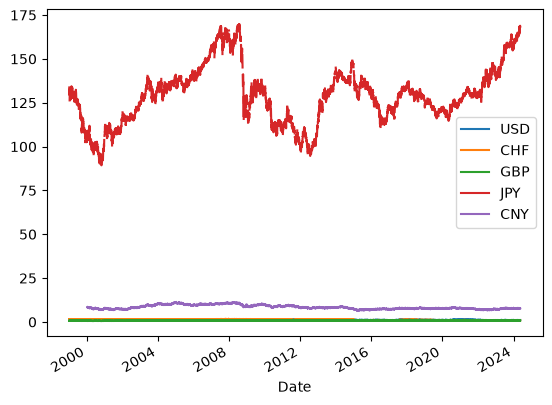

In [84]:
taux_change.plot.line();

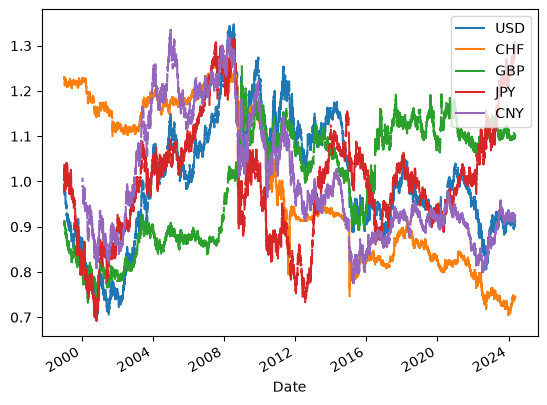

In [85]:
(taux_change/taux_change.mean()).plot.line();

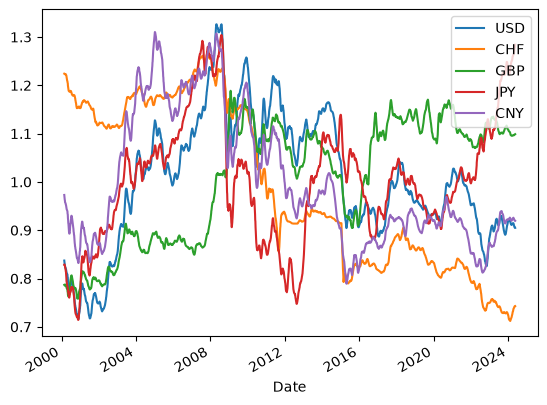

In [88]:
(taux_change/taux_change.mean()).dropna().rolling(30).mean().plot.line();

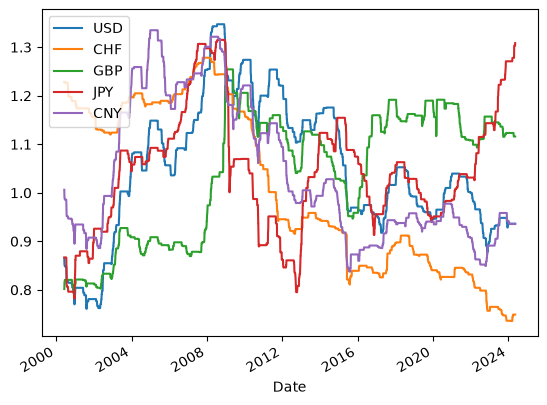

In [89]:
(taux_change/taux_change.mean()).dropna().rolling(100).max().plot.line();

In [90]:
taux_change.iloc[-1]

USD      1.0832
CHF      0.9800
GBP      0.8584
JPY    168.4300
CNY      7.8212
Name: 2024-05-15 00:00:00, dtype: float64

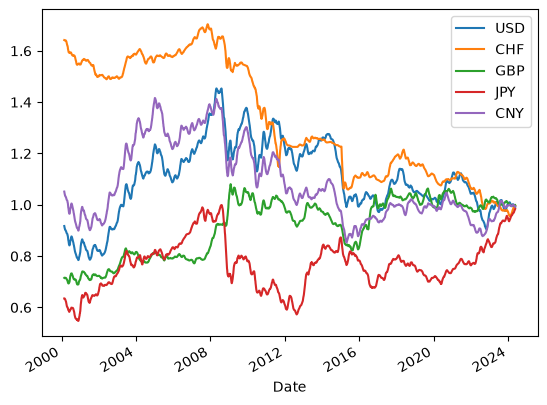

In [92]:
(taux_change/taux_change.iloc[-1]).dropna().rolling(30).mean().plot.line();

In [93]:
taux_change = taux_change.dropna()
taux_change

,USD,CHF,GBP,JPY,CNY
Date,,,,,
2000-01-13,1.0276,1.6111,0.62550,108.89,8.5054
2000-01-14,1.0225,1.6130,0.62210,108.05,8.4632
2000-01-17,1.0094,1.6136,0.61800,105.81,8.3548
2000-01-18,1.0093,1.6131,0.61740,106.42,8.3540
2000-01-19,1.0105,1.6120,0.61720,106.99,8.3639
...,...,...,...,...,...
2024-05-09,1.0732,0.9760,0.85995,167.32,7.7554
2024-05-10,1.0779,0.9779,0.86055,167.87,7.7877
2024-05-13,1.0795,0.9784,0.86023,168.25,7.8095


In [94]:
taux_change.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 6229 entries, 2000-01-13 to 2024-05-15
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   USD     6229 non-null   float64
 1   CHF     6229 non-null   float64
 2   GBP     6229 non-null   float64
 3   JPY     6229 non-null   float64
 4   CNY     6229 non-null   float64
dtypes: float64(5)
memory usage: 292.0 KB


In [96]:
new_index = pd.date_range(taux_change.index[0], taux_change.index[-1], freq="D")
new_index

DatetimeIndex(['2000-01-13', '2000-01-14', '2000-01-15', '2000-01-16',
               '2000-01-17', '2000-01-18', '2000-01-19', '2000-01-20',
               '2000-01-21', '2000-01-22',
               ...
               '2024-05-06', '2024-05-07', '2024-05-08', '2024-05-09',
               '2024-05-10', '2024-05-11', '2024-05-12', '2024-05-13',
               '2024-05-14', '2024-05-15'],
              dtype='datetime64[us]', length=8890, freq='D')

In [97]:
taux_change2 = taux_change.reindex(new_index)
taux_change2

,USD,CHF,GBP,JPY,CNY
2000-01-13,1.0276,1.6111,0.62550,108.89,8.5054
2000-01-14,1.0225,1.6130,0.62210,108.05,8.4632
2000-01-15,NaN,NaN,NaN,NaN,NaN
2000-01-16,NaN,NaN,NaN,NaN,NaN
2000-01-17,1.0094,1.6136,0.61800,105.81,8.3548
...,...,...,...,...,...
2024-05-11,NaN,NaN,NaN,NaN,NaN
2024-05-12,NaN,NaN,NaN,NaN,NaN
2024-05-13,1.0795,0.9784,0.86023,168.25,7.8095
2024-05-14,1.0796,0.9801,0.85983,168.89,7.8103


In [99]:
taux_change2.ffill()

,USD,CHF,GBP,JPY,CNY
2000-01-13,1.0276,1.6111,0.62550,108.89,8.5054
2000-01-14,1.0225,1.6130,0.62210,108.05,8.4632
2000-01-15,1.0225,1.6130,0.62210,108.05,8.4632
2000-01-16,1.0225,1.6130,0.62210,108.05,8.4632
2000-01-17,1.0094,1.6136,0.61800,105.81,8.3548
...,...,...,...,...,...
2024-05-11,1.0779,0.9779,0.86055,167.87,7.7877
2024-05-12,1.0779,0.9779,0.86055,167.87,7.7877
2024-05-13,1.0795,0.9784,0.86023,168.25,7.8095
2024-05-14,1.0796,0.9801,0.85983,168.89,7.8103


In [100]:
taux_change2.bfill()

,USD,CHF,GBP,JPY,CNY
2000-01-13,1.0276,1.6111,0.62550,108.89,8.5054
2000-01-14,1.0225,1.6130,0.62210,108.05,8.4632
2000-01-15,1.0094,1.6136,0.61800,105.81,8.3548
2000-01-16,1.0094,1.6136,0.61800,105.81,8.3548
2000-01-17,1.0094,1.6136,0.61800,105.81,8.3548
...,...,...,...,...,...
2024-05-11,1.0795,0.9784,0.86023,168.25,7.8095
2024-05-12,1.0795,0.9784,0.86023,168.25,7.8095
2024-05-13,1.0795,0.9784,0.86023,168.25,7.8095
2024-05-14,1.0796,0.9801,0.85983,168.89,7.8103


In [101]:
taux_change2.interpolate()

,USD,CHF,GBP,JPY,CNY
2000-01-13,1.027600,1.611100,0.625500,108.890000,8.505400
2000-01-14,1.022500,1.613000,0.622100,108.050000,8.463200
2000-01-15,1.018133,1.613200,0.620733,107.303333,8.427067
2000-01-16,1.013767,1.613400,0.619367,106.556667,8.390933
2000-01-17,1.009400,1.613600,0.618000,105.810000,8.354800
...,...,...,...,...,...
2024-05-11,1.078433,0.978067,0.860443,167.996667,7.794967
2024-05-12,1.078967,0.978233,0.860337,168.123333,7.802233
2024-05-13,1.079500,0.978400,0.860230,168.250000,7.809500
2024-05-14,1.079600,0.980100,0.859830,168.890000,7.810300


## 3. Organismes de formation

Fichier CSV zippé avec des organismes de formation : `ListeOF.zip`

- Charger le fichier directement dans un DataFrame.
- A partir du nombre de valeurs non nulles des colonnes, styliser un DataFrame avec une barre de couleur, en utilisant la méthode `.style.bar()`.
- A partir du pourcentage de remplissage des colonnes arrondi à un chiffre, styliser un DataFrame avec une colormap, en utilisant la méthode `.style.background_gradient()`.

Voir la stylisation des dataframes : https://pandas.pydata.org/docs/user_guide/style.html

## 4. Autres données télécom

Fichier Excel sur le haut débit : `FranceTHD_Open_Data_Observatoire_Juin2015.xlsx`

**Exercice complet de correction des données**

0. Charger la feuille intitulée "Communes" à partir du fichier Excel dans un dataframe en utilisant la seconde ligne comme entête des colonnes et en renommant les colonnes comme suit : 
`"Département", "Code INSEE", "Commune",
"1 Mbit", "3 Mbit", "8 Mbit", "30 Mbit", "100 Mbit",
"DSL 1 Mbit", "DSL 3 Mbit", "DSL 8 Mbit", "DSL 30 Mbit", "DSL 100 Mbit",
"Câble 1 Mbit", "Câble 3 Mbit", "Câble 8 Mbit", "Câble 30 Mbit", "Câble 100 Mbit",
"Fibre 1 Mbit", "Fibre 3 Mbit", "Fibre 8 Mbit", "Fibre 30 Mbit", "Fibre 100 Mbit"`
1. Effectuer la sélection des communes commençant par "Saint" à partir du dataframe. Quel
message obtient-on ?
2. Utiliser l'option `na=False` de la méthode `.str.startswith()` pour éliminer le message d'erreur.
Attention, ce n'est pas parce qu'on a éliminé le message d'erreur que le problème est résolu !
3. Certains noms de ville ne sont donc pas des chaînes de caractères car la méthode
`.str.startswith()` ne retourne pas systématiquement un booléen. Sélectionner les lignes pour
lesquelles la méthode `.str.startswith()` retourne un `NaN`. Il y a 2 communes dont le nom est le
booléen `False` !
5. Pour vérifier, donner le décompte des types de la colonne "Commune". En fait, ces communes
s'appellent `"Faux"`, mais la valeur `"Faux"` a été interprétée dans le fichier Excel comme le `FAUX`
logique et elle a été ensuite interprétée par **pandas** comme le booléen `False` au moment de
l'import des données.
6. Donner une méthode plus simple pour sélectionner les lignes avec le nom de commune à `False`.
7. Pour finir, affectez la valeur `"Faux"` lorsque l'objet n'est pas une chaîne.
8. Les données sont enfin corrigées...
9. ... et la requête initiale fonctionne

## 5. Villes du monde

Télécharger le dataset avec les villes du monde de plus de 500 habitants :
- http://www.geonames.org/
- http://download.geonames.org/export/dump/cities500.zip

**Data Preparation**
- Dans un premier temps, charger les données dans un DataFrame avec comme noms de colonnes <code>['geonameid', 'name', 'asciiname', 'alternatenames', 'latitude', 'longitude', 'feature class', 'feature code', 'country code', 'cc2', 'admin1 code', 'admin2 code', 'admin3 code', 'admin4 code', 'population', 'elevation', 'dem', 'timezone', 'modification date']</code>
- On obtient un warning sur des types mixtes : parmi les colonnes qui sont des chaînes de caractères, quelles sont celles qui comportent également des nombres ? (appliquer la méthode de chaîne `isdigit()` sur les colonnes de type `object`).
- Compter le nombre de valeurs manquantes dans chaque colonne : quelle colonnes ne devraient pas avoir de valeurs manquantes ?
- Appliquer `describe()` sur le DataFrame complet, quelle valeur semble être également une valeur manquante ?
- Recharger les données en passant en `str` les colonnes mixtes et en précisant les valeurs manquantes.

**Split-apply-combine strategy**
- Ecrire une fonction qui trouve le nombre de `alternatenames` de chaque ville.
```python
def average_alternate_names(group):
    pass
```
- Calculer la moyenne du nombre de `alternatenames` par `feature code`.

**Jointure**

- Charger le tableau de la page https://www.geonames.org/countries/ avec la fonction <code>pandas.read_html()</code> en prenant garde aux valeurs manquantes par défaut.
- Joindre le DataFrame des villes avec celui des pays.
- Ecrire une fonction qui retourne le nom de la ville la plus peuplée et la tester sur le DataFrame obtenu.
- Appliquer la fonction en groupant par continent.

**Recherche géographique**
- Il est possible de reprendre les fonctions `ville()` et `gps2dec()` définies lors de la première session et les utiliser avec ce nouveau jeu de données.